# **1.Import Libraries**

In [99]:
from google.colab import drive

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import unicodedata

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# **2.Import Data from Google Drive**

In [9]:
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Arabic_Spam/Arabic_Spam.csv'

df = pd.read_csv(
    file_path,
    encoding='utf-8-sig'
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **3.Understand Data**

In [14]:
df = df.rename(columns={
    'SMS': 'message',
    'Sentiment': 'label'
})

print("Dataset Head:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicated Messages:", df.duplicated(subset='message').sum())

label_distribution = pd.DataFrame({
    'Count': df['label'].value_counts().sort_index(),
    'Percentage': df['label'].value_counts(normalize=True).sort_index() * 100
})

label_distribution.index = ['Ham (0)', 'Spam (1)']

print("\nLabel Distribution:")
display(label_distribution.round(2))


Dataset Head:


,message,label
0,مصرف الراجحي تم إيقاف حسابك لتنشيط الحساب اتصل...,1
1,!! إغلاق !!\nحسابك في الراجحي اتصل الان.\n٠٥٨١...,1
2,عزيزنا العميل، \nنود اعلامك بأنه سوف يتم تعليق...,1
3,عزيز العميل!تنبيه\nحسابك بنك الراجحي لاتعمل تص...,1
4,حساب تسجيل الدخول الجديد (usdtrust.top): tkkae...,1



Dataset Shape: (494, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 494 entries, 0 to 493
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   message  494 non-null    object
 1   label    494 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 7.8+ KB

Missing Values:
message    0
label      0
dtype: int64

Duplicated Messages: 31

Label Distribution:


,Count,Percentage
Ham (0),330,66.8
Spam (1),164,33.2


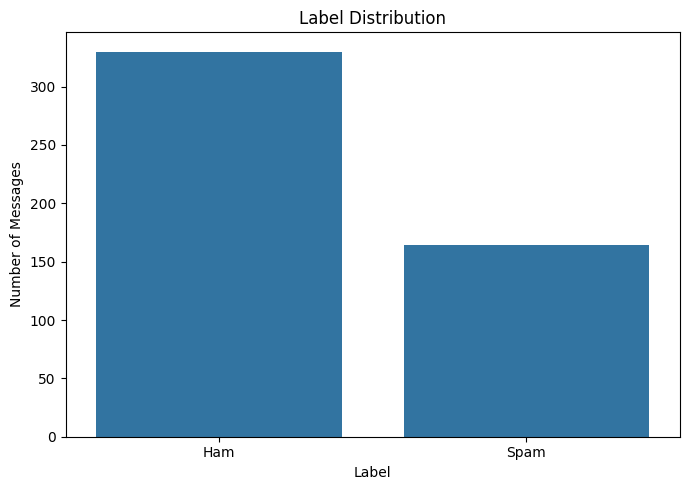

In [16]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='label'
)

plt.title('Label Distribution')
plt.xlabel('Label')
plt.ylabel('Number of Messages')

plt.xticks(
    ticks=[0, 1],
    labels=['Ham', 'Spam']
)

plt.tight_layout()
plt.show()


# **4.Data Cleaning**

In [17]:
print("Duplicates Before Cleaning:", df.duplicated(subset='message').sum())

df = df.drop_duplicates(subset='message').copy()

print("Duplicates After Cleaning:", df.duplicated(subset='message').sum())
print("Dataset Shape After Cleaning:", df.shape)

Duplicates Before Cleaning: 31
Duplicates After Cleaning: 0
Dataset Shape After Cleaning: (463, 2)


In [32]:
def clean_text(text):
    text = unicodedata.normalize('NFKC', str(text))

    text = text.lower()

    text = re.sub(
        r'https?://\S+|www\.\S+|\b[\w-]+\.(?:com|net|org|top|info)\b',
        ' URLTOKEN ',
        text
    )

    text = ''.join(
        char for char in text
        if unicodedata.category(char) != 'Mn' and char != '\u0674'
    )

    text = text.replace('ـ', '')

    text = re.sub(r'[أإآٱ]', 'ا', text)
    text = text.replace('ى', 'ي')
    text = text.replace('ی', 'ي')
    text = text.replace('ک', 'ك')

    text = re.sub(r'(?<=\d),(?=\d)', '', text)

    text = re.sub(r'[^\w\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [33]:
df['cleaned_message'] = df['message'].apply(clean_text)

display(df[['message', 'cleaned_message']].head(10))

,message,cleaned_message
0,مصرف الراجحي تم إيقاف حسابك لتنشيط الحساب اتصل...,مصرف الراجحي تم ايقاف حسابك لتنشيط الحساب اتصل...
1,!! إغلاق !!\nحسابك في الراجحي اتصل الان.\n٠٥٨١...,اغلاق حسابك في الراجحي اتصل الان ٠٥٨١٨٩٢٨٠٤
2,عزيزنا العميل، \nنود اعلامك بأنه سوف يتم تعليق...,عزيزنا العميل نود اعلامك بانه سوف يتم تعليق خد...
3,عزيز العميل!تنبيه\nحسابك بنك الراجحي لاتعمل تص...,عزيز العميل تنبيه حسابك بنك الراجحي لاتعمل تصل...
4,حساب تسجيل الدخول الجديد (usdtrust.top): tkkae...,حساب تسجيل الدخول الجديد URLTOKEN tkkae كلمة ا...
5,تعال وانضم إلينا في كأس العالم 2022 في قطر واك...,تعال وانضم الينا في كاس العالم 2022 في قطر واك...
6,لدينا أشياء عظيمة لك ! قم بدعوة أصدقائك للانضم...,لدينا اشياء عظيمة لك قم بدعوة اصدقائك للانضمام...
7,"[9:43 PM, 3/4/2023] أمي الحبيبة: اتصال جديد (u...",9 43 pm 3 4 2023 امي الحبيبة اتصال جديد URLTOK...
8,مرحبًا. أنا مدير توظيف في STZ. بسبب الشواغر. س...,مرحبا انا مدير توظيف في stz بسبب الشواغر سوف ن...
9,"عزیزي العمیل ، لقد ربحت جاٸزة 200,000 ماٸتي أ...",عزيزي العميل لقد ربحت جايزة 200000 مايتي الف ر...


In [34]:
print("Dataset Shape After Cleaning:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nEmpty Cleaned Messages:")
print((df['cleaned_message'].str.strip() == '').sum())

Dataset Shape After Cleaning:
(463, 3)

Missing Values:
message            0
label              0
cleaned_message    0
dtype: int64

Duplicate Rows:
0

Empty Cleaned Messages:
0


# **5.Feature Engineering**

In [44]:
df['message_length'] = df['cleaned_message'].str.len()

df['word_count'] = df['cleaned_message'].str.split().str.len()

In [45]:
print("Feature Statistics:")
display(df[['message_length', 'word_count']].describe())

Feature Statistics:


,message_length,word_count
count,463.000000,463.000000
mean,47.965443,8.874730
std,48.276966,8.695017
min,2.000000,1.000000
25%,15.500000,3.000000
50%,33.000000,6.000000
75%,65.000000,12.000000
max,420.000000,70.000000


In [47]:
feature_comparison = df.groupby('label')[
    ['message_length', 'word_count']
].mean()

feature_comparison.index = ['Ham', 'Spam']

print("\nAverage Features by Label:")
display(feature_comparison.round(2))


Average Features by Label:


,message_length,word_count
Ham,29.02,5.58
Spam,84.89,15.30


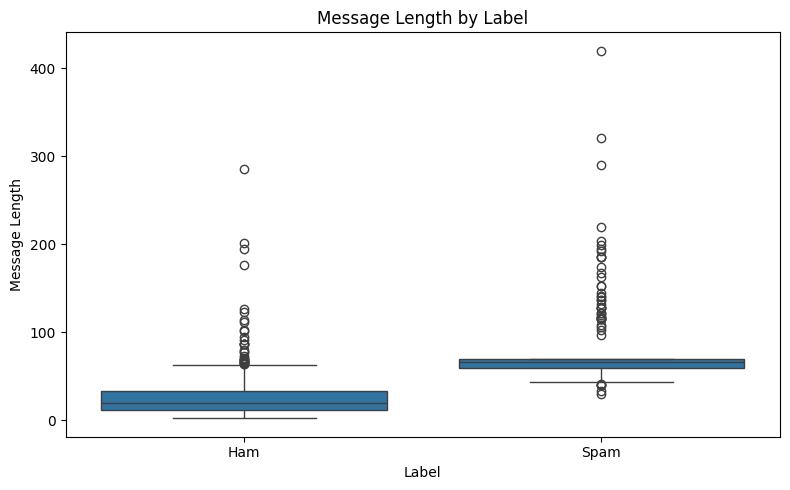

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='label',
    y='message_length'
)

plt.title('Message Length by Label')
plt.xlabel('Label')
plt.ylabel('Message Length')
plt.xticks(ticks=[0, 1], labels=['Ham', 'Spam'])

plt.tight_layout()
plt.show()

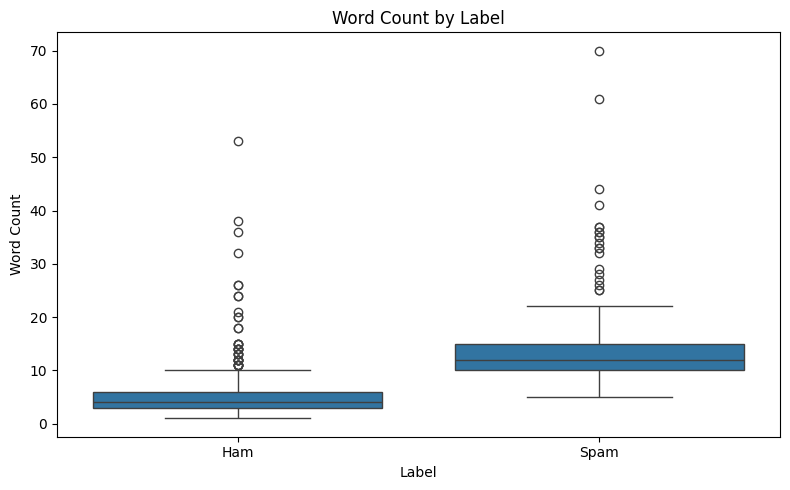

In [49]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='label',
    y='word_count'
)

plt.title('Word Count by Label')
plt.xlabel('Label')
plt.ylabel('Word Count')
plt.xticks(ticks=[0, 1], labels=['Ham', 'Spam'])

plt.tight_layout()
plt.show()


Correlation Between Numerical Features:


,message_length,word_count
message_length,1.000,0.989
word_count,0.989,1.000


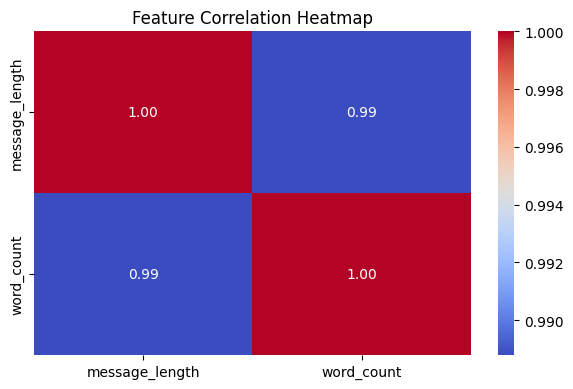

In [50]:
feature_correlation = df[
    ['message_length', 'word_count']
].corr()

print("\nCorrelation Between Numerical Features:")
display(feature_correlation.round(3))

plt.figure(figsize=(6, 4))

sns.heatmap(
    feature_correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [51]:
df = df.drop(columns=['word_count'])

print("\nDataset After Feature Selection:")
display(df.head())


Dataset After Feature Selection:


,message,label,cleaned_message,message_length
0,مصرف الراجحي تم إيقاف حسابك لتنشيط الحساب اتصل...,1,مصرف الراجحي تم ايقاف حسابك لتنشيط الحساب اتصل...,61
1,!! إغلاق !!\nحسابك في الراجحي اتصل الان.\n٠٥٨١...,1,اغلاق حسابك في الراجحي اتصل الان ٠٥٨١٨٩٢٨٠٤,43
2,عزيزنا العميل، \nنود اعلامك بأنه سوف يتم تعليق...,1,عزيزنا العميل نود اعلامك بانه سوف يتم تعليق خد...,420
3,عزيز العميل!تنبيه\nحسابك بنك الراجحي لاتعمل تص...,1,عزيز العميل تنبيه حسابك بنك الراجحي لاتعمل تصل...,132
4,حساب تسجيل الدخول الجديد (usdtrust.top): tkkae...,1,حساب تسجيل الدخول الجديد URLTOKEN tkkae كلمة ا...,108


# **6.Data Splitting**

In [52]:
X = df['cleaned_message']
y = df['label']

In [53]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [54]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [55]:
print("Training Set Shape:", X_train.shape)
print("Validation Set Shape:", X_val.shape)
print("Testing Set Shape:", X_test.shape)

Training Set Shape: (324,)
Validation Set Shape: (69,)
Testing Set Shape: (70,)


In [56]:
label_distribution = pd.DataFrame({
    'Training': y_train.value_counts(normalize=True),
    'Validation': y_val.value_counts(normalize=True),
    'Test': y_test.value_counts(normalize=True)
}).T * 100

label_distribution = label_distribution.rename(
    columns={0: 'Ham (%)', 1: 'Spam (%)'}
)

print("\nLabel Distribution Across Datasets:")
display(label_distribution.round(2))



Label Distribution Across Datasets:


label,Ham (%),Spam (%)
Training,66.05,33.95
Validation,66.67,33.33
Test,65.71,34.29


# **7.Feature Extraction using TF-IDF**

In [78]:
tfidf_vectorizer = TfidfVectorizer()

In [79]:
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_val_tfidf = tfidf_vectorizer.transform(X_val)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [80]:
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Validation TF-IDF Shape:", X_val_tfidf.shape)
print("Test TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (324, 1564)
Validation TF-IDF Shape: (69, 1564)
Test TF-IDF Shape: (70, 1564)


In [82]:
vocabulary_size = len(tfidf_vectorizer.vocabulary_)

print("Vocabulary Size:", vocabulary_size)

print("\nSample Vocabulary Terms:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

Vocabulary Size: 1564

Sample Vocabulary Terms:
['00' '01' '0112267444' '02' '03' '04' '0531268115' '0537518254'
 '0552347310' '0558526232' '0561108380' '0572112694' '0573239824'
 '0582793054' '0590273143' '0593374138' '0594389853' '0596462942'
 '0596577303' '0596866932']


# **8.Model Building & Training**

***Experiment 1: Logistic Regression***

In [83]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [84]:
y_pred_lr = lr_model.predict(X_val_tfidf)

In [85]:
print("Logistic Regression - Validation Results")

print("\nAccuracy:", accuracy_score(y_val, y_pred_lr))

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred_lr,
    labels=[0, 1],
    target_names=['ham', 'spam'],
    zero_division=0
))

Logistic Regression - Validation Results

Accuracy: 0.8695652173913043

Classification Report:
              precision    recall  f1-score   support

         ham       0.88      0.93      0.91        46
        spam       0.85      0.74      0.79        23

    accuracy                           0.87        69
   macro avg       0.86      0.84      0.85        69
weighted avg       0.87      0.87      0.87        69



Confusion Matrix:
[[43  3]
 [ 6 17]]


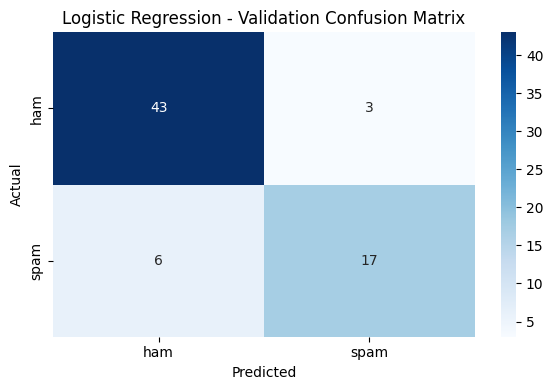

In [86]:
cm_lr = confusion_matrix(
    y_val,
    y_pred_lr,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Validation Confusion Matrix')

plt.tight_layout()
plt.show()

***Experiment 2: Linear SVM***

In [87]:
svm_model = LinearSVC(
    max_iter=2000,
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

print("Linear SVM Training Completed!")

Linear SVM Training Completed!


In [88]:
y_pred_svm = svm_model.predict(X_val_tfidf)

In [89]:
print("Linear SVM - Validation Results")

print("\nAccuracy:", accuracy_score(y_val, y_pred_svm))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_pred_svm,
    labels=[0, 1],
    target_names=['Ham', 'Spam'],
    zero_division=0
))

Linear SVM - Validation Results

Accuracy: 0.927536231884058

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.91      0.94        46
        Spam       0.85      0.96      0.90        23

    accuracy                           0.93        69
   macro avg       0.91      0.93      0.92        69
weighted avg       0.93      0.93      0.93        69



Confusion Matrix:
[[42  4]
 [ 1 22]]


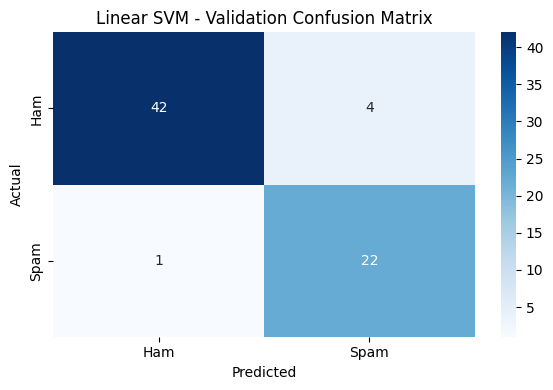

In [90]:
cm_svm = confusion_matrix(
    y_val,
    y_pred_svm,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm_svm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Linear SVM - Validation Confusion Matrix')

plt.tight_layout()
plt.show()

# **9.Hyperparameter Tuning**

***9.1 Logistic Regression Tuning***

In [92]:
C_values = [0.01, 0.1, 1, 10, 100]

lr_results = []

for c in C_values:

    model = LogisticRegression(
        C=c,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_tfidf, y_train)

    y_val_pred = model.predict(X_val_tfidf)

    spam_f1 = f1_score(
        y_val,
        y_val_pred,
        pos_label=1,
        zero_division=0
    )

    lr_results.append({
        'C': c,
        'Spam F1-score': spam_f1
    })

In [93]:
lr_results_df = pd.DataFrame(lr_results)

print("Logistic Regression Tuning Results:")
display(lr_results_df.round(4))


# Select Best Hyperparameter
best_lr_C = lr_results_df.loc[
    lr_results_df['Spam F1-score'].idxmax(),
    'C'
]

print("Best Logistic Regression C:", best_lr_C)

Logistic Regression Tuning Results:


,C,Spam F1-score
0,0.01,0.0000
1,0.10,0.0000
2,1.00,0.7907
3,10.00,0.8936
4,100.00,0.8980


Best Logistic Regression C: 100.0


***9.2 Linear SVM Tuning***

In [95]:
svm_results = []

for c in C_values:

    model = LinearSVC(
        C=c,
        max_iter=2000,
        random_state=42
    )

    model.fit(X_train_tfidf, y_train)

    y_val_pred = model.predict(X_val_tfidf)

    spam_f1 = f1_score(
        y_val,
        y_val_pred,
        pos_label=1
    )

    svm_results.append({
        'C': c,
        'Spam F1-score': spam_f1
    })

In [96]:
svm_results_df = pd.DataFrame(svm_results)

print("Linear SVM Tuning Results:")
display(svm_results_df.round(4))

best_svm_C = svm_results_df.loc[
    svm_results_df['Spam F1-score'].idxmax(),
    'C'
]

print("Best Linear SVM C:", best_svm_C)

Linear SVM Tuning Results:


,C,Spam F1-score
0,0.01,0.0000
1,0.10,0.7619
2,1.00,0.8980
3,10.00,0.8800
4,100.00,0.8800


Best Linear SVM C: 1.0


In [100]:
# 9.3 Compare Best Models

# Best Logistic Regression
best_lr_model = LogisticRegression(
    C=best_lr_C,
    max_iter=1000,
    random_state=42
)

best_lr_model.fit(X_train_tfidf, y_train)

y_pred_best_lr = best_lr_model.predict(X_val_tfidf)


# Best Linear SVM
best_svm_model = LinearSVC(
    C=best_svm_C,
    max_iter=2000,
    random_state=42
)

best_svm_model.fit(X_train_tfidf, y_train)

y_pred_best_svm = best_svm_model.predict(X_val_tfidf)


# Compare Evaluation Metrics
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Linear SVM'],

    'Accuracy': [
        accuracy_score(y_val, y_pred_best_lr),
        accuracy_score(y_val, y_pred_best_svm)
    ],

    'Spam Precision': [
        precision_score(y_val, y_pred_best_lr, pos_label=1),
        precision_score(y_val, y_pred_best_svm, pos_label=1)
    ],

    'Spam Recall': [
        recall_score(y_val, y_pred_best_lr, pos_label=1),
        recall_score(y_val, y_pred_best_svm, pos_label=1)
    ],

    'Spam F1-score': [
        f1_score(y_val, y_pred_best_lr, pos_label=1),
        f1_score(y_val, y_pred_best_svm, pos_label=1)
    ],

    'Macro F1-score': [
        f1_score(y_val, y_pred_best_lr, average='macro'),
        f1_score(y_val, y_pred_best_svm, average='macro')
    ]
})

print("Best Models Comparison:")
display(comparison.round(4))

Best Models Comparison:


,Model,Accuracy,Spam Precision,Spam Recall,Spam F1-score,Macro F1-score
0,Logistic Regression,0.9275,0.8462,0.9565,0.898,0.9209
1,Linear SVM,0.9275,0.8462,0.9565,0.898,0.9209


# **10.Train Final Models**

*10.1 Final Logistic Regression*

In [101]:
final_lr_model = LogisticRegression(
    C=best_lr_C,
    max_iter=1000,
    random_state=42
)

final_lr_model.fit(X_train_tfidf, y_train)

print("Final Logistic Regression Training Completed!")
print("Selected C:", best_lr_C)

Final Logistic Regression Training Completed!
Selected C: 100.0


10.2 Final Linear SVM

In [103]:
final_svm_model = LinearSVC(
    C=best_svm_C,
    max_iter=2000,
    random_state=42
)

final_svm_model.fit(X_train_tfidf, y_train)

print("Final Linear SVM Training Completed!")
print("Selected C:", best_svm_C)

Final Linear SVM Training Completed!
Selected C: 1.0


# **11.Final Predictions**

In [104]:
# Logistic Regression Predictions
y_test_pred_lr = final_lr_model.predict(X_test_tfidf)

# Linear SVM Predictions
y_test_pred_svm = final_svm_model.predict(X_test_tfidf)

print("Final Predictions Completed!")

Final Predictions Completed!


# **12.Final Model Evaluation**

*12.1 Logistic Regression*

In [105]:
print("Logistic Regression - Final Test Results")

print("\nAccuracy:")
print(accuracy_score(y_test, y_test_pred_lr))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_lr,
    labels=[0, 1],
    target_names=['Ham', 'Spam'],
    zero_division=0
))

Logistic Regression - Final Test Results

Accuracy:
0.9714285714285714

Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      0.96      0.98        46
        Spam       0.92      1.00      0.96        24

    accuracy                           0.97        70
   macro avg       0.96      0.98      0.97        70
weighted avg       0.97      0.97      0.97        70



*12.2 Linear SVM*

In [106]:
print("Linear SVM - Final Test Results")

print("\nAccuracy:")
print(accuracy_score(y_test, y_test_pred_svm))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_svm,
    labels=[0, 1],
    target_names=['Ham', 'Spam'],
    zero_division=0
))

Linear SVM - Final Test Results

Accuracy:
0.9714285714285714

Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      0.96      0.98        46
        Spam       0.92      1.00      0.96        24

    accuracy                           0.97        70
   macro avg       0.96      0.98      0.97        70
weighted avg       0.97      0.97      0.97        70



# **13.Confusion Matrices**

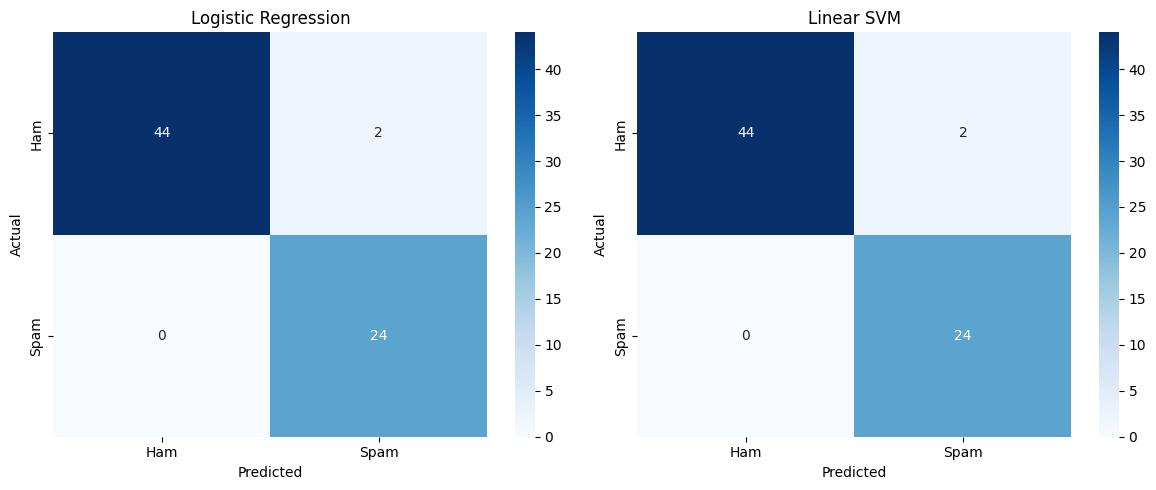

In [107]:
# Generate Confusion Matrices
cm_lr = confusion_matrix(
    y_test,
    y_test_pred_lr,
    labels=[0, 1]
)

cm_svm = confusion_matrix(
    y_test,
    y_test_pred_svm,
    labels=[0, 1]
)


# Create Side-by-Side Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


# Logistic Regression
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam'],
    ax=axes[0]
)

axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')


# Linear SVM
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam'],
    ax=axes[1]
)

axes[1].set_title('Linear SVM')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')


plt.tight_layout()
plt.show()

# **14.Final Model Comparison**

In [108]:
lr_report = classification_report(
    y_test,
    y_test_pred_lr,
    labels=[0, 1],
    target_names=['Ham', 'Spam'],
    output_dict=True,
    zero_division=0
)

svm_report = classification_report(
    y_test,
    y_test_pred_svm,
    labels=[0, 1],
    target_names=['Ham', 'Spam'],
    output_dict=True,
    zero_division=0
)


# Create Comparison Table
comparison_df = pd.DataFrame({
    'Metric': [
        'Best C',
        'Accuracy',
        'Spam Precision',
        'Spam Recall',
        'Spam F1-score',
        'Macro F1-score'
    ],

    'Logistic Regression': [
        best_lr_C,
        accuracy_score(y_test, y_test_pred_lr),
        lr_report['Spam']['precision'],
        lr_report['Spam']['recall'],
        lr_report['Spam']['f1-score'],
        lr_report['macro avg']['f1-score']
    ],

    'Linear SVM': [
        best_svm_C,
        accuracy_score(y_test, y_test_pred_svm),
        svm_report['Spam']['precision'],
        svm_report['Spam']['recall'],
        svm_report['Spam']['f1-score'],
        svm_report['macro avg']['f1-score']
    ]
})


print("Final Model Comparison:")
display(comparison_df.round(4))

Final Model Comparison:


,Metric,Logistic Regression,Linear SVM
0,Best C,100.0000,1.0000
1,Accuracy,0.9714,0.9714
2,Spam Precision,0.9231,0.9231
3,Spam Recall,1.0000,1.0000
4,Spam F1-score,0.9600,0.9600
5,Macro F1-score,0.9689,0.9689


# **15. Final Conclusion**

In this project, two machine learning models, Logistic Regression and Linear SVM, were developed for Arabic SMS Spam Classification using TF-IDF feature extraction.

Hyperparameter tuning was performed using the validation set to select the best C values for both models:
- Logistic Regression: C = 100
- Linear SVM: C = 1

Both models achieved strong and identical performance on the test set, with an accuracy of 97.14% and a Spam F1-score of 0.96.

Both models achieved 100% Spam Recall, successfully detecting all 24 spam messages in the test set. They also achieved 92% Spam Precision, indicating that a small number of legitimate messages were incorrectly classified as spam.

Since both models achieved identical results across the evaluated metrics, neither model demonstrated a clear performance advantage over the other.

Therefore, both Logistic Regression and Linear SVM can be considered suitable models for Arabic SMS Spam Classification based on the current test results.